# Time Series Data Preparation

**Workstream:** time-series data preparation | **Milestone:** Review 2 | **Owner:** [@Achilles80](https://github.com/Achilles80)

This notebook prepares the data for the time series analysis stage. It **builds on `data/processed/features.csv`**, the cleaned zone-hour demand table from the processing stage, and turns it into regular hourly and daily demand series at four levels (all zones, borough, service area and individual zone). Next to the target it adds everything a time series model needs: a calendar and event table, seasonal Fourier terms, weather regressors, a daylight-saving adjustment, train/validation/test splits and rolling-origin folds.

**Why not use `features.csv` as it is?** It was built for the machine-learning models, and time series analysis needs things it does not have:

| Need | `features.csv` | This dataset |
|---|---|---|
| Full, unbroken history from 1 Sep 2025 | starts 8 Sep (first week dropped for the 168 h lag warm-up) | starts 1 Sep: the first week is recovered exactly from its own `trip_count_lag_168h` column |
| Series at aggregate levels (city, borough, service area) and daily frequency | zone-hour only | hourly + daily, 4 levels |
| The DST double hour handled | flagged in docs only | flag + adjusted target + affected-lag flags |
| Holiday names, holiday periods, special days and nights | one `is_holiday` flag | full event calendar (EDA G9 recommendations) |
| Seasonal regressors for ARIMA/regression models | none | daily and weekly Fourier terms |
| Splits that match the ML test period, plus CV folds | split done later in the modelling notebook | built in, same test window as the models |
| Per-zone series type (smooth / intermittent ...) | none | computed on training data only |

**Inputs** (all in the repository, so no Kaggle download is needed): `data/processed/features.csv` (the base), `data/raw/weather_hourly_by_zone.csv` (weather and weather grid cells), `data/raw/taxi_zones_manhattan_queens.csv` (borough and service area), `data/processed/cleaning_report.md` (cross-check of the total) and `models/modeling/split_summary.csv` (the ML test period).

**Outputs:** everything goes to `data/processed/time_series/`. Field descriptions and design decisions: `data/dataset-documents/time_series_preparation.md`.

Run all cells top to bottom (about 2 minutes).

## 0. Setup

### 0.1 Imports and settings

`holidays` gives the official US federal holiday calendar, and `statsmodels` is used only for the readiness diagnostics at the end (stationarity tests and autocorrelation).

All fixed definitions live in this cell, so they can be checked in one place:

- **Study window.** 1 Sep 2025 00:00 to 28 Feb 2026 23:00, local New York time.
- **Event dates.** Taken from the EDA (`scripts/eda_arun.py`), so the two stages use the same definitions. The NYC Marathon date comes from the NYRR results page.
- **Time bands.** The same six bands the EDA used.
- **Heavy snow day.** The median across zones of daily snowfall is at least 5 cm, the same rule as the EDA.

In [1]:
import re
import warnings
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf, adfuller, kpss

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# Folders (the notebook lives in scripts/, data is at the project root)
ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
OUT = PROCESSED / "time_series"
FIG = ROOT / "data" / "dataset-documents" / "figures" / "time_series"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

WEATHER_FILE = RAW / "weather_hourly_by_zone.csv"
ZONES_FILE = RAW / "taxi_zones_manhattan_queens.csv"
FEATURES_FILE = PROCESSED / "features.csv"               # the base of this dataset
CLEANING_REPORT = PROCESSED / "cleaning_report.md"       # cross-check only
MODEL_SPLIT_FILE = ROOT / "models" / "modeling" / "split_summary.csv"

# Study window (naive local New York time, same clock as the TLC timestamps)
START = pd.Timestamp("2025-09-01 00:00")
END = pd.Timestamp("2026-02-28 23:00")
WEATHER_VARS = ["apparent_temperature", "rain", "snowfall", "precipitation_probability"]

# Daylight saving ended at 02:00 on 2 Nov 2025: 01:00-01:59 happened twice
DST_HOUR = pd.Timestamp("2025-11-02 01:00")

# Event definitions shared with the EDA (scripts/eda_arun.py)
SPECIAL_DAYS = {
    "2025-10-31": "Halloween",
    "2025-11-02": "NYC Marathon",
    "2025-11-28": "Black Friday",
    "2025-12-24": "Christmas Eve",
    "2025-12-31": "New Year's Eve",
}
NIGHT_EVENTS = [  # cross-midnight windows, 20:00 to 04:59
    ("Halloween night", "2025-10-31 20:00", "2025-11-01 04:00"),
    ("New Year's Eve night", "2025-12-31 20:00", "2026-01-01 04:00"),
]
HOLIDAY_PERIODS = [
    ("Thanksgiving week", "2025-11-24", "2025-11-30"),
    ("Christmas-New Year", "2025-12-20", "2026-01-04"),
]
TIME_BANDS = (
    [-1, 4, 6, 9, 15, 19, 23],
    ["Late night 00-04", "Early morning 05-06", "AM 07-09", "Midday 10-15", "PM 16-19", "Evening 20-23"],
)
HEAVY_SNOW_CM = 5.0
NO_EVENT = "none"           # text value on ordinary days (a blank would be read back as missing)
VALIDATION_HOURS = 14 * 24   # two weeks just before the test period
HOLIDAY_DISTANCE_CAP = 14    # days; holiday effects further away than two weeks are not meaningful
FOURIER_K = 3                # harmonics for each seasonal period

print("Project root:", ROOT)

Project root: D:\College\nyc-taxi-demand-forecasting


### 0.2 Check log

Every check in the notebook goes through `check()`. It stops the notebook if a check fails, and records the result so all checks can be saved together at the end (`ts_readiness_checks.csv`).

In [2]:
CHECKS = []


def check(name, passed, detail=""):
    CHECKS.append({"check": name, "passed": bool(passed), "detail": detail})
    status = "PASS" if passed else "FAIL"
    print(f"[{status}] {name}: {detail}")
    if not passed:
        raise AssertionError(f"{name} failed: {detail}")

## 1. Load `features.csv` and recover the first week

`features.csv` is the cleaned zone-hour demand table from the processing stage (`scripts/data_processing_engineering.ipynb`): 138 zones × 4,176 hours, from 8 Sep 2025. It already has the four cleaning rules applied, zero-demand hours filled in, and weather and calendar columns joined. This notebook uses it as its base, so the time series dataset continues directly from the team's processing work.

The processing stage dropped **1-7 Sep** (168 hours × 138 zones = 23,184 zone-hours) because its 168-hour lag needs a full week of history. Time series models don't need that warm-up, and the first week contains Labor Day, so it is worth getting back.

It can be recovered **exactly**. The processing stage computed `trip_count_lag_168h` on the complete zero-filled grid, sorted by time within each zone, *before* it dropped the warm-up rows. So for each row from 8-14 Sep, `trip_count_lag_168h` is the zone's count exactly one week earlier, on 1-7 Sep. The EDA used the same fact for its trip reconciliation (A7).

The recovery is not just assumed. Three checks prove it:
1. On every row where both values are in the file (15 Sep onwards), `trip_count_lag_168h` equals `trip_count` 168 hours earlier. The lag column is exact everywhere it can be tested.
2. The recovered 7 Sep counts agree with two *other* lag columns: `trip_count_lag_24h` of each 8 Sep hour, and `trip_count_lag_1h` of 8 Sep 00:00.
3. The total of the rebuilt panel equals the **22,579,793** clean trips in `cleaning_report.md`, so no demand is lost or counted twice.

In [3]:
features = pd.read_csv(FEATURES_FILE, parse_dates=["pickup_hour"])
features = features.sort_values(["PULocationID", "pickup_hour"]).reset_index(drop=True)
print(f"features.csv: {len(features):,} rows, {features['PULocationID'].nunique()} zones, "
      f"{features['pickup_hour'].min()} -> {features['pickup_hour'].max()}")

hours = pd.date_range(START, END, freq="h")
FIRST_KEPT = features["pickup_hour"].min()          # 8 Sep 00:00, first hour after the warm-up week
check("features.csv starts one week after the study start", FIRST_KEPT == START + pd.Timedelta(hours=168), str(FIRST_KEPT))

# check 1: the 168 h lag equals the count one week earlier wherever both are in the file
earlier = features[["PULocationID", "pickup_hour", "trip_count"]].assign(
    pickup_hour=lambda d: d["pickup_hour"] + pd.Timedelta(hours=168))
lag_test = features.merge(earlier, on=["PULocationID", "pickup_hour"], suffixes=("", "_week_before"))
check("trip_count_lag_168h is exact wherever it can be tested",
      (lag_test["trip_count_lag_168h"] == lag_test["trip_count_week_before"]).all(),
      f"{len(lag_test):,} zone-hours compared")

# recover 1-7 Sep from the lag of 8-14 Sep
first_week = (features.loc[features["pickup_hour"] < FIRST_KEPT + pd.Timedelta(hours=168),
                           ["PULocationID", "pickup_hour", "trip_count_lag_168h"]]
              .assign(pickup_hour=lambda d: d["pickup_hour"] - pd.Timedelta(hours=168))
              .rename(columns={"trip_count_lag_168h": "trip_count"}))
check("First week recovered for every zone and hour", len(first_week) == 138 * 168, f"{len(first_week):,} zone-hours")

# check 2: the recovered 7 Sep values agree with the 24 h and 1 h lags of 8 Sep
day8 = features[features["pickup_hour"] < FIRST_KEPT + pd.Timedelta(hours=24)]
sep7 = first_week.assign(pickup_hour=lambda d: d["pickup_hour"] + pd.Timedelta(hours=24))
c24 = day8.merge(sep7, on=["PULocationID", "pickup_hour"], suffixes=("", "_recovered"))
sep7_last = first_week[first_week["pickup_hour"] == FIRST_KEPT - pd.Timedelta(hours=1)].set_index("PULocationID")["trip_count"]
c1 = day8[day8["pickup_hour"] == FIRST_KEPT].set_index("PULocationID")["trip_count_lag_1h"]
check("Recovered 7 Sep agrees with trip_count_lag_24h and trip_count_lag_1h",
      (c24["trip_count_lag_24h"] == c24["trip_count_recovered"]).all() and c1.sort_index().equals(sep7_last.sort_index()),
      f"{len(c24):,} + {len(c1)} values compared")

features.csv: 576,288 rows, 138 zones, 2025-09-08 00:00:00 -> 2026-02-28 23:00:00
[PASS] features.csv starts one week after the study start: 2025-09-08 00:00:00


[PASS] trip_count_lag_168h is exact wherever it can be tested: 553,104 zone-hours compared
[PASS] First week recovered for every zone and hour: 23,184 zone-hours
[PASS] Recovered 7 Sep agrees with trip_count_lag_24h and trip_count_lag_1h: 3,312 + 138 values compared


## 2. Zone-hour panel

### 2.1 Combine into one complete grid

The recovered first week and `features.csv` are stacked into one panel: 138 zones × 4,344 hours. The grid is checked against the weather table, which has one row for every zone and hour of the study period. Zero-demand hours are kept as **0**, as in `features.csv`: they are real observations of no demand, and a time series must not have holes.

Weather is taken from `data/raw/weather_hourly_by_zone.csv` for all hours, because `features.csv` has no rows for the first week. For 8 Sep onwards it must be identical to the weather columns in `features.csv`, and the check below confirms this.

In [4]:
panel = (pd.concat([first_week, features[["PULocationID", "pickup_hour", "trip_count"]]], ignore_index=True)
         .rename(columns={"pickup_hour": "ds"}))
panel["trip_count"] = panel["trip_count"].astype("int32")

weather = pd.read_csv(WEATHER_FILE, parse_dates=["weather_hour"])
zone_weather = (weather[["LocationID", "weather_hour", *WEATHER_VARS]]
                .rename(columns={"LocationID": "PULocationID", "weather_hour": "ds"}))
panel = zone_weather.merge(panel, on=["PULocationID", "ds"], how="left", validate="one_to_one")
panel = panel.sort_values(["PULocationID", "ds"]).reset_index(drop=True)

check("Grid is 138 zones x 4,344 hours with no missing counts",
      len(panel) == 138 * len(hours) and panel["trip_count"].notna().all() and panel["PULocationID"].nunique() == 138,
      f"{len(panel):,} rows, {len(hours):,} hours")
check("Hourly index is regular (no gaps or repeats)",
      (panel.groupby("PULocationID")["ds"].diff().dropna() == pd.Timedelta(hours=1)).all(),
      "every step within each zone is exactly 1 hour")

# check 3: the total equals the clean trips in the cleaning report
report = CLEANING_REPORT.read_text(encoding="utf-8")
n_clean = int(re.search(r"Final clean rows:\*\*\s*([\d,]+)", report).group(1).replace(",", ""))
check("Total demand equals the clean trips in cleaning_report.md", int(panel["trip_count"].sum()) == n_clean,
      f"{int(panel['trip_count'].sum()):,} trips")

w_cmp = features.merge(panel, left_on=["PULocationID", "pickup_hour"], right_on=["PULocationID", "ds"], suffixes=("_features", ""))
check("Weather equals the weather columns of features.csv",
      all((w_cmp[f"{v}_features"] == w_cmp[v]).all() for v in WEATHER_VARS), f"{len(w_cmp):,} zone-hours compared")

[PASS] Grid is 138 zones x 4,344 hours with no missing counts: 599,472 rows, 4,344 hours
[PASS] Hourly index is regular (no gaps or repeats): every step within each zone is exactly 1 hour
[PASS] Total demand equals the clean trips in cleaning_report.md: 22,579,793 trips


[PASS] Weather equals the weather columns of features.csv: 576,288 zone-hours compared


### 2.3 Daylight-saving adjustment

TLC timestamps are local wall-clock times with no UTC offset. When the clocks went back on 2 Nov 2025, the hour 01:00-01:59 happened twice, and both physical hours are recorded with the same `01:00` label. That one label therefore holds about two hours of pickups.

The hourly index is kept on local wall-clock time. It stays perfectly regular (4,344 labels, no gaps), and "hour of day" keeps its everyday meaning. To stop the doubled hour from distorting models:

- `trip_count` keeps the observed count (nothing is thrown away)
- `trip_count_adj` divides that single hour by 2, the number of physical hours it covers, so it measures **pickups per physical hour** like every other row
- the calendar table flags the hour (`is_dst_merged_hour`) and the hours whose 24 h and 168 h lags point at it

City-wide, the adjusted value (4,583) sits between the hours before (8,735) and after (3,423), so the series stays smooth.

In [5]:
panel["trip_count_adj"] = panel["trip_count"].astype("float64")
panel.loc[panel["ds"] == DST_HOUR, "trip_count_adj"] /= 2

city = panel.groupby("ds")[["trip_count", "trip_count_adj"]].sum()
print(city.loc[DST_HOUR - pd.Timedelta(hours=2): DST_HOUR + pd.Timedelta(hours=2)])
check("DST adjustment only touches the merged hour",
      (panel["trip_count"] != panel["trip_count_adj"]).groupby(panel["ds"]).any().loc[lambda s: s].index.tolist() == [DST_HOUR],
      f"adjusted hour: {DST_HOUR}")

                     trip_count  trip_count_adj
ds                                             
2025-11-01 23:00:00        8503          8503.0
2025-11-02 00:00:00        8735          8735.0
2025-11-02 01:00:00        9166          4583.0
2025-11-02 02:00:00        3423          3423.0
2025-11-02 03:00:00        2672          2672.0
[PASS] DST adjustment only touches the merged hour: adjusted hour: 2025-11-02 01:00:00


## 3. Calendar and event table

One row per hour (4,344 rows) with every time-related regressor. These features are all **known in advance**: the calendar, published holidays and scheduled events. That makes them safe to use when forecasting. The only exception is `is_heavy_snow_day`, which comes from the weather data, so it is only known in advance through a weather forecast. The same applies to the weather columns, as explained in the documentation.

### 3.1 Basic calendar fields, time index and time bands

- `t` counts hours from the start (0-4,343). It is the trend variable for regression-style models.
- `day_index` and `week_index` count days and weeks. 1 Sep 2025 is a Monday, so `week_index` lines up with Monday-to-Sunday weeks.
- `hour_of_week` (0-167) is the position in the weekly cycle and the natural key for weekly profiles.
- `night_date` assigns the hours 00:00-04:59 to the previous evening, the way the EDA treats nights. `is_weekend_night` is Friday or Saturday night, 20:00-04:59.

In [6]:
cal = pd.DataFrame({"ds": hours})
cal["date"] = cal["ds"].dt.normalize()
cal["t"] = np.arange(len(cal))
cal["day_index"] = (cal["date"] - START.normalize()).dt.days
cal["week_index"] = cal["day_index"] // 7
cal["hour"] = cal["ds"].dt.hour
cal["day_of_week"] = cal["ds"].dt.dayofweek            # 0 = Monday
cal["day_name"] = cal["ds"].dt.day_name()
cal["is_weekend"] = cal["day_of_week"] >= 5
cal["month"] = cal["ds"].dt.month
cal["day_of_month"] = cal["ds"].dt.day
cal["hour_of_week"] = cal["day_of_week"] * 24 + cal["hour"]
cal["time_band"] = pd.cut(cal["hour"], TIME_BANDS[0], labels=TIME_BANDS[1]).astype(str)

night_date = (cal["ds"] - pd.Timedelta(hours=5)).dt.normalize()   # 00-04 belongs to the evening before
is_night = (cal["hour"] >= 20) | (cal["hour"] <= 4)
cal["is_weekend_night"] = is_night & night_date.dt.dayofweek.isin([4, 5])

check("Week index starts on a Monday", START.dayofweek == 0, f"{START.date()} is a {START.day_name()}")
cal.head()

[PASS] Week index starts on a Monday: 2025-09-01 is a Monday


,ds,date,t,day_index,week_index,hour,day_of_week,day_name,is_weekend,month,day_of_month,hour_of_week,time_band,is_weekend_night
0,2025-09-01 00:00:00,2025-09-01,0,0,0,0,0,Monday,False,9,1,0,Late night 00-04,False
1,2025-09-01 01:00:00,2025-09-01,1,0,0,1,0,Monday,False,9,1,1,Late night 00-04,False
2,2025-09-01 02:00:00,2025-09-01,2,0,0,2,0,Monday,False,9,1,2,Late night 00-04,False
3,2025-09-01 03:00:00,2025-09-01,3,0,0,3,0,Monday,False,9,1,3,Late night 00-04,False
4,2025-09-01 04:00:00,2025-09-01,4,0,0,4,0,Monday,False,9,1,4,Late night 00-04,False


### 3.2 Holidays, holiday periods, special days and night events

These follow the EDA's recommendations (G9 in `EDA_doc/EDA_findings.md`). The EDA found large differences between individual holidays: Christmas Day was −58% against a normal day of the same weekday, Columbus Day −8%, MLK Day about 0%. One shared flag can't capture that, so the table keeps the holiday **name** as well:

- **Federal holidays** come from the `holidays` package. All 8 in the window are kept, including Labor Day (1 Sep), which `features.csv` lost with its warm-up week. `days_to_next_holiday` and `days_since_prev_holiday` also count holidays outside the window (4 July 2025 and Memorial Day 2026), so the values at the edges are correct. Both are **capped at 14 days**. Without the cap, the test period would reach 97 days (late February, waiting for Memorial Day) while training never goes above 41, and a model would be extrapolating. Being 30 or 90 days from a holiday makes no difference to demand anyway.
- `holiday_name` is kept to describe and analyse individual holidays. It should not be used as a model input: MLK Day and Washington's Birthday fall only in the validation and test periods, so a model could never learn them from training data. Use `is_holiday` for modelling.
- **Holiday periods:** Thanksgiving week and the Christmas-New Year period. The EDA measured −24% and −27% for these.
- **Special days:** Halloween, NYC Marathon (also the DST day), Black Friday, Christmas Eve and New Year's Eve.
- On ordinary days the name columns hold the value `none` (not a blank), so they read back without missing values.
- **Night events:** the Halloween and New Year's Eve nights run from 20:00 to 04:59 across midnight. A calendar-day flag would split them in two. The EDA measured +62% for New Year's Eve night.

In [7]:
us_holidays = holidays.US(years=[2025, 2026])
hol = pd.Series({pd.Timestamp(d): name for d, name in us_holidays.items()}).sort_index()
hol_in_window = hol[(hol.index >= START.normalize()) & (hol.index <= END.normalize())]
print(hol_in_window.to_string())
check("8 federal holidays in the window", len(hol_in_window) == 8, ", ".join(hol_in_window.values))

cal["is_holiday"] = cal["date"].isin(hol_in_window.index)
cal["holiday_name"] = cal["date"].map(hol_in_window).fillna(NO_EVENT)
cal["is_day_before_holiday"] = (cal["date"] + pd.Timedelta(days=1)).isin(hol.index)
cal["is_day_after_holiday"] = (cal["date"] - pd.Timedelta(days=1)).isin(hol.index)

hol_dates = hol.index.values
pos_next = np.searchsorted(hol_dates, cal["date"].values, side="left")
pos_prev = np.searchsorted(hol_dates, cal["date"].values, side="right") - 1
cal["days_to_next_holiday"] = (pd.to_datetime(hol_dates[pos_next]) - cal["date"]).dt.days.clip(upper=HOLIDAY_DISTANCE_CAP)
cal["days_since_prev_holiday"] = (cal["date"] - pd.to_datetime(hol_dates[pos_prev])).dt.days.clip(upper=HOLIDAY_DISTANCE_CAP)

cal["holiday_period"] = NO_EVENT
for name, first, last in HOLIDAY_PERIODS:
    cal.loc[cal["date"].between(first, last), "holiday_period"] = name
cal["is_holiday_period"] = cal["holiday_period"] != NO_EVENT

cal["special_day_name"] = cal["date"].dt.strftime("%Y-%m-%d").map(SPECIAL_DAYS).fillna(NO_EVENT)
cal["is_special_day"] = cal["special_day_name"] != NO_EVENT

cal["night_event_name"] = NO_EVENT
for name, first, last in NIGHT_EVENTS:
    cal.loc[cal["ds"].between(first, last), "night_event_name"] = name
cal["is_night_event"] = cal["night_event_name"] != NO_EVENT

# the holiday flag must agree with features.csv wherever both exist
flag_cmp = features.drop_duplicates("pickup_hour").merge(cal[["ds", "is_holiday"]], left_on="pickup_hour", right_on="ds")
check("Holiday flag matches features.csv", (flag_cmp["is_holiday_x"] == flag_cmp["is_holiday_y"]).all(),
      f"{len(flag_cmp):,} hours compared")

2025-09-01                     Labor Day
2025-10-13                  Columbus Day
2025-11-11                  Veterans Day
2025-11-27              Thanksgiving Day
2025-12-25                 Christmas Day
2026-01-01                New Year's Day
2026-01-19    Martin Luther King Jr. Day
2026-02-16         Washington's Birthday
[PASS] 8 federal holidays in the window: Labor Day, Columbus Day, Veterans Day, Thanksgiving Day, Christmas Day, New Year's Day, Martin Luther King Jr. Day, Washington's Birthday
[PASS] Holiday flag matches features.csv: 4,176 hours compared


### 3.3 Daylight-saving flags and heavy-snow days

- `is_dst_merged_hour` marks the doubled 01:00 on 2 Nov. `is_dst_lag24_affected` and `is_dst_lag168_affected` mark the hours exactly 24 h and 168 h later, because any 24 h or 168 h lag feature there reads the doubled value. The EDA recommended flagging both.
- `is_heavy_snow_day` uses the EDA's rule: the median across all 138 zones of daily snowfall is at least 5 cm. Five days qualify, and three of them (25 Jan, 22 and 23 Feb 2026) fall in the **test period**. 25 Jan, with about 19 cm, is by far the biggest storm in the data and is the first day of the test period. Anyone evaluating forecasts needs to know this.

In [8]:
cal["is_dst_merged_hour"] = cal["ds"] == DST_HOUR
cal["is_dst_lag24_affected"] = cal["ds"] == DST_HOUR + pd.Timedelta(hours=24)
cal["is_dst_lag168_affected"] = cal["ds"] == DST_HOUR + pd.Timedelta(hours=168)

weather["date"] = weather["weather_hour"].dt.normalize()
city_daily_snow = weather.groupby(["date", "LocationID"])["snowfall"].sum().groupby("date").median()
heavy_snow_days = city_daily_snow[city_daily_snow >= HEAVY_SNOW_CM]
print("Heavy snow days (median zone snowfall, cm):")
print(heavy_snow_days.round(1).to_string())
cal["is_heavy_snow_day"] = cal["date"].isin(heavy_snow_days.index)

Heavy snow days (median zone snowfall, cm):
date
2025-12-14     6.0
2025-12-26     5.5
2026-01-25    19.2
2026-02-22     9.0
2026-02-23    13.9


### 3.4 Seasonal Fourier terms

Taxi demand repeats every **24 hours** (daily cycle) and every **168 hours** (weekly cycle). The EDA found that a zone's weekly pattern correlates at a median of 0.90 with its other weeks.

Fourier terms describe those cycles as a few smooth sine/cosine waves: $\sin(2\pi k\,h/P)$ and $\cos(2\pi k\,h/P)$ for $k = 1..3$. They are the standard way to put long seasonal periods into ARIMA errors (dynamic harmonic regression), linear regression or Prophet-style models. A seasonal ARIMA with a 168-hour period is very slow to fit, and these terms avoid that.

Three harmonics per period gives 12 columns. They also work as cyclical encodings: `fourier_daily_sin_1`/`cos_1` place 23:00 next to 00:00. Only six months of data are available, so no yearly seasonality is added.

In [9]:
for k in range(1, FOURIER_K + 1):
    cal[f"fourier_daily_sin_{k}"] = np.sin(2 * np.pi * k * cal["hour"] / 24).round(6)
    cal[f"fourier_daily_cos_{k}"] = np.cos(2 * np.pi * k * cal["hour"] / 24).round(6)
    cal[f"fourier_weekly_sin_{k}"] = np.sin(2 * np.pi * k * cal["hour_of_week"] / 168).round(6)
    cal[f"fourier_weekly_cos_{k}"] = np.cos(2 * np.pi * k * cal["hour_of_week"] / 168).round(6)

### 3.5 Train / validation / test split

Time series must be split **by time**, never shuffled. The **test** period is taken from `models/modeling/split_summary.csv`, so time series forecasts are scored on exactly the same 836 hours (25 Jan 2026 04:00 - 28 Feb 2026 23:00) as the naive baseline, Linear Regression, Random Forest and Gradient Boosting. That makes the results directly comparable.

The two weeks just before the test period (336 hours) become a **validation** set for choosing model orders and settings. Everything earlier, from 1 Sep, is **train**. The ML models' training data started on 8 Sep, but time series models have no lag warm-up to drop, so they get the first week as well.

Daily series use the same calendar days: train up to 10 Jan, validation 11-24 Jan, test 25 Jan - 28 Feb.

In [10]:
model_split = pd.read_csv(MODEL_SPLIT_FILE, parse_dates=["start", "end"]).set_index("dataset")
TEST_START = model_split.loc["test", "start"]
VAL_START = TEST_START - pd.Timedelta(hours=VALIDATION_HOURS)
check("Test period ends at the end of the data", model_split.loc["test", "end"] == END, f"{TEST_START} -> {END}")

cal["split"] = np.select([cal["ds"] >= TEST_START, cal["ds"] >= VAL_START], ["test", "validation"], "train")
cal["split_daily"] = np.select([cal["date"] >= TEST_START.normalize(), cal["date"] >= VAL_START.normalize()],
                               ["test", "validation"], "train")

split_table = cal.groupby("split", sort=False)["ds"].agg(["min", "max", "count"]).rename(columns={"count": "hours"})
print(split_table)
check("Test hours match the ML models", split_table.loc["test", "hours"] == model_split.loc["test", "timestamps"],
      f"{split_table.loc['test', 'hours']} hours")

[PASS] Test period ends at the end of the data: 2026-01-25 04:00:00 -> 2026-02-28 23:00:00
                           min                 max  hours
split                                                    
train      2025-09-01 00:00:00 2026-01-11 03:00:00   3172
validation 2026-01-11 04:00:00 2026-01-25 03:00:00    336
test       2026-01-25 04:00:00 2026-02-28 23:00:00    836
[PASS] Test hours match the ML models: 836 hours


### 3.6 Rolling-origin cross-validation folds

A single validation window can be lucky or unlucky. The usual time series alternative is **rolling-origin evaluation**: fit on everything up to a cut-off, forecast the next 7 days, move the cut-off forward a week, and repeat. These six weekly folds cover the six weeks before the test period, including the Christmas-New Year holidays. Each fold trains only on data before its window, so no fold ever sees the test period.

In [11]:
n_folds = 6
last_window_end = TEST_START.normalize() - pd.Timedelta(hours=1)      # 24 Jan 23:00
folds = []
for i in range(n_folds):
    window_end = last_window_end - pd.Timedelta(days=7 * (n_folds - 1 - i))
    window_start = window_end - pd.Timedelta(days=7) + pd.Timedelta(hours=1)
    folds.append({"fold": i + 1, "train_start": START, "train_end": window_start - pd.Timedelta(hours=1),
                  "forecast_start": window_start, "forecast_end": window_end,
                  "forecast_hours": 168, "forecast_days": 7})
cv_folds = pd.DataFrame(folds)
check("CV folds stay before the test period", (cv_folds["forecast_end"] < TEST_START).all(), f"{n_folds} folds")
cv_folds

[PASS] CV folds stay before the test period: 6 folds


,fold,train_start,train_end,forecast_start,forecast_end,forecast_hours,forecast_days
0,1,2025-09-01,2025-12-13 23:00:00,2025-12-14,2025-12-20 23:00:00,168,7
1,2,2025-09-01,2025-12-20 23:00:00,2025-12-21,2025-12-27 23:00:00,168,7
2,3,2025-09-01,2025-12-27 23:00:00,2025-12-28,2026-01-03 23:00:00,168,7
3,4,2025-09-01,2026-01-03 23:00:00,2026-01-04,2026-01-10 23:00:00,168,7
4,5,2025-09-01,2026-01-10 23:00:00,2026-01-11,2026-01-17 23:00:00,168,7
5,6,2025-09-01,2026-01-17 23:00:00,2026-01-18,2026-01-24 23:00:00,168,7


## 4. Aggregate series (hourly and daily)

Time series analysis usually starts with a few strong, smooth series before going down to individual zones. Six series are built at three levels:

| Level | Series |
|---|---|
| `city` | `All zones` (Manhattan + Queens) |
| `borough` | `Manhattan`, `Queens` |
| `service_area` | `Yellow Zone`, `Boro Zone`, `Airports` (TLC service areas) |

For each series and hour, the table has: the observed and DST-adjusted counts, $\log(1+y)$ of the adjusted count, how many zones it covers, and the **mean weather across its zones**.

A plain mean is used for the weather, not one weighted by demand. Weighting by the current hour's pickups would let the target leak into a regressor.

Why provide $\log(1+y)$: the EDA found demand strongly right-skewed and overdispersed (variance larger than the mean in 135 of 136 zones). A log transform evens out the variance, which ARIMA and ETS models assume. $\log(1+y)$ also keeps zero hours valid.

Every row also carries all the calendar columns, so a single series is ready to use straight away.

In [12]:
zones = pd.read_csv(ZONES_FILE)[["LocationID", "Borough", "Zone", "service_zone", "latitude", "longitude"]]
pz = panel.merge(zones.rename(columns={"LocationID": "PULocationID"}), on="PULocationID", how="left", validate="many_to_one")
pz["all"] = "All zones"


def hourly_series(level, key):
    out = (pz.groupby([key, "ds"])
             .agg(trip_count=("trip_count", "sum"), trip_count_adj=("trip_count_adj", "sum"),
                  n_zones=("PULocationID", "nunique"),
                  **{v: (v, "mean") for v in WEATHER_VARS})
             .reset_index().rename(columns={key: "series_id"}))
    out.insert(0, "series_level", level)
    return out


agg_hourly = pd.concat([hourly_series("city", "all"), hourly_series("borough", "Borough"),
                        hourly_series("service_area", "service_zone")], ignore_index=True)
agg_hourly[WEATHER_VARS] = agg_hourly[WEATHER_VARS].round(3)
agg_hourly["log1p_trip_count_adj"] = np.log1p(agg_hourly["trip_count_adj"]).round(6)
agg_hourly = agg_hourly.merge(cal, on="ds", how="left", validate="many_to_one")

for level, n_series in [("city", 1), ("borough", 2), ("service_area", 3)]:
    sub = agg_hourly[agg_hourly["series_level"] == level]
    check(f"{level} series add up to all clean trips",
          int(sub["trip_count"].sum()) == n_clean and sub["series_id"].nunique() == n_series and len(sub) == n_series * len(hours),
          f"{sub['series_id'].nunique()} series, {int(sub['trip_count'].sum()):,} trips")
agg_hourly.groupby(["series_level", "series_id"], sort=False)["trip_count"].agg(["sum", "mean", "max"]).round(1)

[PASS] city series add up to all clean trips: 1 series, 22,579,793 trips
[PASS] borough series add up to all clean trips: 2 series, 22,579,793 trips
[PASS] service_area series add up to all clean trips: 3 series, 22,579,793 trips


sum    mean    max
series_level series_id                           
city         All zones    22579793  5197.9  12648
borough      Manhattan    20431943  4703.5  11843
             Queens        2147850   494.4   1449
service_area Airports      1468045   337.9   1058
             Boro Zone     1639075   377.3   1172
             Yellow Zone  19472673  4482.7  11277

### 4.1 Daily series

Daily totals are smoother and easier to use for a first decomposition, for weekly seasonal ARIMA (period 7), or for ETS. The weather is summarised per day: temperature mean, minimum and maximum; rain and snow **totals**; precipitation probability mean and maximum; and the number of hours with rain or snow.

The day-level calendar fields are kept, and weekly Fourier terms for a 7-day period are added. `contains_dst_merged_hour` marks 2 Nov, whose `trip_count` includes the extra hour, while `trip_count_adj` does not.

In [13]:
day_cal_cols = ["date", "day_index", "week_index", "day_of_week", "day_name", "is_weekend", "month", "day_of_month",
                "is_holiday", "holiday_name", "is_day_before_holiday", "is_day_after_holiday",
                "days_to_next_holiday", "days_since_prev_holiday", "holiday_period", "is_holiday_period",
                "special_day_name", "is_special_day", "is_heavy_snow_day", "split_daily"]
day_cal = cal[day_cal_cols].drop_duplicates("date").rename(columns={"split_daily": "split"}).reset_index(drop=True)
day_cal["contains_dst_merged_hour"] = day_cal["date"] == DST_HOUR.normalize()
for k in range(1, FOURIER_K + 1):
    day_cal[f"fourier_weekly_sin_{k}"] = np.sin(2 * np.pi * k * day_cal["day_of_week"] / 7).round(6)
    day_cal[f"fourier_weekly_cos_{k}"] = np.cos(2 * np.pi * k * day_cal["day_of_week"] / 7).round(6)


def to_daily(hourly, keys):
    h = hourly.assign(date=hourly["ds"].dt.normalize(),
                      rain_hour=hourly["rain"] > 0, snow_hour=hourly["snowfall"] > 0)
    return (h.groupby(keys + ["date"])
             .agg(trip_count=("trip_count", "sum"), trip_count_adj=("trip_count_adj", "sum"),
                  apparent_temperature_mean=("apparent_temperature", "mean"),
                  apparent_temperature_min=("apparent_temperature", "min"),
                  apparent_temperature_max=("apparent_temperature", "max"),
                  rain_total=("rain", "sum"), snowfall_total=("snowfall", "sum"),
                  precipitation_probability_mean=("precipitation_probability", "mean"),
                  precipitation_probability_max=("precipitation_probability", "max"),
                  rain_hours=("rain_hour", "sum"), snow_hours=("snow_hour", "sum"))
             .reset_index())


agg_daily = to_daily(agg_hourly, ["series_level", "series_id"])
agg_daily = agg_daily.merge(agg_hourly.groupby(["series_id"])["n_zones"].first().reset_index(), on="series_id")
agg_daily["log1p_trip_count_adj"] = np.log1p(agg_daily["trip_count_adj"]).round(6)
agg_daily = agg_daily.merge(day_cal, on="date", how="left", validate="many_to_one")
weather_daily_cols = [c for c in agg_daily.columns if c.startswith(("apparent_", "rain_total", "snowfall_total", "precipitation_"))]
agg_daily[weather_daily_cols] = agg_daily[weather_daily_cols].round(3)

check("Daily totals equal hourly totals",
      agg_daily.groupby("series_id")["trip_count"].sum().equals(agg_hourly.groupby("series_id")["trip_count"].sum()),
      f"{agg_daily['date'].nunique()} days x {agg_daily['series_id'].nunique()} series")
agg_daily[agg_daily["series_id"] == "All zones"].head()

[PASS] Daily totals equal hourly totals: 181 days x 6 series


,series_level,series_id,date,trip_count,trip_count_adj,apparent_temperature_mean,apparent_temperature_min,apparent_temperature_max,rain_total,snowfall_total,precipitation_probability_mean,precipitation_probability_max,rain_hours,snow_hours,n_zones,log1p_trip_count_adj,day_index,week_index,day_of_week,day_name,...,day_of_month,is_holiday,holiday_name,is_day_before_holiday,is_day_after_holiday,days_to_next_holiday,days_since_prev_holiday,holiday_period,is_holiday_period,special_day_name,is_special_day,is_heavy_snow_day,split,contains_dst_merged_hour,fourier_weekly_sin_1,fourier_weekly_cos_1,fourier_weekly_sin_2,fourier_weekly_cos_2,fourier_weekly_sin_3,fourier_weekly_cos_3
362,city,All zones,2025-09-01,88614,88614.0,20.300,16.136,24.667,0.046,0.0,0.059,0.884,1,0,138,11.392056,0,0,0,Monday,...,1,True,Labor Day,False,False,0,0,none,False,none,False,False,train,False,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
363,city,All zones,2025-09-02,110182,110182.0,20.412,15.619,25.522,0.000,0.0,0.069,1.000,0,0,138,11.609898,1,0,1,Tuesday,...,2,False,none,False,True,14,1,none,False,none,False,False,train,False,0.781831,0.623490,0.974928,-0.222521,0.433884,-0.900969
364,city,All zones,2025-09-03,123146,123146.0,20.345,15.291,27.017,0.000,0.0,0.000,0.000,0,0,138,11.721134,2,0,2,Wednesday,...,3,False,none,False,False,14,2,none,False,none,False,False,train,False,0.974928,-0.222521,-0.433884,-0.900969,-0.781831,0.623490
365,city,All zones,2025-09-04,141155,141155.0,20.909,16.705,25.904,0.220,0.0,5.399,42.949,2,0,138,11.857621,3,0,3,Thursday,...,4,False,none,False,False,14,3,none,False,none,False,False,train,False,0.433884,-0.900969,-0.781831,0.623490,0.974928,-0.222521
366,city,All zones,2025-09-05,136437,136437.0,24.844,20.572,29.674,0.586,0.0,5.848,58.145,1,0,138,11.823626,4,0,4,Friday,...,5,False,none,False,False,14,4,none,False,none,False,False,train,False,-0.433884,-0.900969,0.781831,0.623490,-0.974928,-0.222521


## 5. Zone-level series

### 5.1 Zone hourly panel and zone daily series

The zone hourly panel (599,472 rows) is kept **narrow**: zone, hour, the counts and the zone's own weather. All calendar fields are the same for every zone, so they stay in the 4,344-row calendar table and are joined on `ds` when needed. The panel then stays under GitHub's file-size limits:

```python
panel = pd.read_csv("ts_zone_hourly.csv", parse_dates=["ds"]).merge(
    pd.read_csv("ts_calendar_hourly.csv", parse_dates=["ds", "date"]), on="ds")
```

In [14]:
zone_hourly = panel[["PULocationID", "ds", "trip_count", "trip_count_adj", *WEATHER_VARS]].copy()

zone_daily = to_daily(panel, ["PULocationID"])
zone_daily = zone_daily.merge(day_cal[["date", "split"]], on="date", how="left", validate="many_to_one")
zone_daily[[c for c in zone_daily.columns if c.startswith(("apparent_", "rain_total", "snowfall_total", "precipitation_"))]] = \
    zone_daily[[c for c in zone_daily.columns if c.startswith(("apparent_", "rain_total", "snowfall_total", "precipitation_"))]].round(3)

check("Zone daily covers 138 zones x 181 days", len(zone_daily) == 138 * 181, f"{len(zone_daily):,} rows")

[PASS] Zone daily covers 138 zones x 181 days: 24,978 rows


### 5.2 Zone profiles: which series can be modelled on their own?

The 138 zone series behave very differently. Upper East Side South averages about 240 pickups an hour, while the EDA found 40 zones averaging less than one pickup an hour and two zones (103 and 104) with no pickups at all. One method can't suit all of them, so every zone gets a profile. **The profile uses only the training period**, so the test period can't influence any modelling choice.

- **Volume tier** by mean pickups per hour: High (≥ 50), Medium (10-50), Low (1-10), Sparse (> 0 and < 1), Zero.
- **Demand pattern** uses the standard Syntetos-Boylan classification, based on how often a zone has demand and how variable it is when it does:
  - **ADI** (average demand interval) = number of hours ÷ number of hours with at least one pickup
  - **CV²** = squared coefficient of variation of the non-zero hourly counts
  - *smooth*: ADI < 1.32 and CV² < 0.49
  - *erratic*: ADI < 1.32 and CV² ≥ 0.49
  - *intermittent*: ADI ≥ 1.32 and CV² < 0.49
  - *lumpy*: ADI ≥ 1.32 and CV² ≥ 0.49
- **Suggested approach.** Smooth and erratic zones can be forecast individually (ARIMA, ETS, regression). Intermittent and lumpy zones need intermittent-demand methods such as Croston or TSB, or should be pooled into their borough or service-area series. Zones with no training demand are only forecast at aggregate level.

`weather_cell_id` records which Open-Meteo grid cell each zone's weather comes from. The 138 zones use 50 cells, so zones in one cell are not independent weather observations.

In [15]:
train_panel = panel[panel["ds"] < VAL_START]
check("Zone profiles use training hours only", train_panel["ds"].max() < VAL_START, f"last hour used: {train_panel['ds'].max()}")


def zone_stats(g):
    y = g["trip_count_adj"]
    nonzero = y[y > 0]
    adi = len(y) / len(nonzero) if len(nonzero) else np.nan
    cv2 = (nonzero.std(ddof=0) / nonzero.mean()) ** 2 if len(nonzero) > 1 else np.nan
    return pd.Series({"train_hours": len(y), "train_total_trips": y.sum(), "train_mean": y.mean(),
                      "train_median": y.median(), "train_std": y.std(ddof=0), "train_p95": y.quantile(0.95),
                      "train_max": y.max(), "train_zero_share": (y == 0).mean(), "adi": adi, "cv2": cv2})


profile = train_panel.groupby("PULocationID").apply(zone_stats, include_groups=False).reset_index()
profile["volume_tier"] = pd.cut(profile["train_mean"], [-np.inf, 0, 1, 10, 50, np.inf], right=False,
                                labels=["Zero", "Sparse", "Low", "Medium", "High"]).astype(str)
profile.loc[profile["train_mean"] == 0, "volume_tier"] = "Zero"
smooth_freq = profile["adi"] < 1.32
low_var = profile["cv2"] < 0.49
profile["demand_pattern"] = np.select(
    [profile["adi"].isna(), smooth_freq & low_var, smooth_freq & ~low_var, ~smooth_freq & low_var],
    ["no demand", "smooth", "erratic", "intermittent"], "lumpy")
profile["suggested_approach"] = np.select(
    [profile["demand_pattern"].isin(["smooth", "erratic"]), profile["demand_pattern"].isin(["intermittent", "lumpy"])],
    ["individual series model", "intermittent-demand method or pool to aggregate"], "aggregate level only")

cells = weather.groupby("LocationID")[["grid_latitude", "grid_longitude"]].first()
cell_ids = {key: f"cell_{i + 1:02d}" for i, key in enumerate(sorted(set(map(tuple, cells.values))))}
cells["weather_cell_id"] = [cell_ids[tuple(v)] for v in cells.values]
profile = (zones.rename(columns={"LocationID": "PULocationID"})
           .merge(profile, on="PULocationID", how="left", validate="one_to_one")
           .merge(cells["weather_cell_id"], left_on="PULocationID", right_index=True, how="left"))
round_cols = ["train_mean", "train_median", "train_std", "train_p95", "train_max", "train_zero_share", "adi", "cv2", "train_total_trips"]
profile[round_cols] = profile[round_cols].round(4)

print(profile["volume_tier"].value_counts().to_string(), "\n")
print(profile["demand_pattern"].value_counts().to_string())
check("Every zone has a profile and a weather cell", profile["weather_cell_id"].notna().all() and len(profile) == 138,
      f"{profile['weather_cell_id'].nunique()} weather cells")

[PASS] Zone profiles use training hours only: last hour used: 2026-01-11 03:00:00


volume_tier
Sparse    39
High      39
Low       34
Medium    24
Zero       2 

demand_pattern
smooth          48
intermittent    43
erratic         35
lumpy           10
no demand        2
[PASS] Every zone has a profile and a weather cell: 50 weather cells


## 6. Readiness diagnostics

These checks show the series are ready for modelling and tell the analysis stage where to start. All of them use the **training period only**.

### 6.1 Stationarity

ARIMA-type models need a stationary series. Two complementary tests are run on the hourly and daily `All zones` series:

- **ADF** tests the null hypothesis that the series has a unit root (is non-stationary). A small p-value is evidence of stationarity.
- **KPSS** tests the null hypothesis that the series *is* stationary. A small p-value is evidence of non-stationarity.

A series is called ready when both agree: ADF p < 0.05 and KPSS p > 0.05. Each test is applied to the log series, its seasonal difference and its seasonal plus first difference. The results suggest the differencing orders (d, D) for the analysis stage.

KPSS only reports p-values between 0.01 and 0.10, so anything outside that range is shown at the boundary.

In [16]:
train_city_h = agg_hourly[(agg_hourly["series_id"] == "All zones") & (agg_hourly["split"] == "train")].set_index("ds")["log1p_trip_count_adj"]
train_city_d = agg_daily[(agg_daily["series_id"] == "All zones") & (agg_daily["split"] == "train")].set_index("date")["log1p_trip_count_adj"]

variants = {
    ("hourly", "log1p level"): train_city_h,
    ("hourly", "seasonal difference (168 h)"): train_city_h.diff(168),
    ("hourly", "seasonal (168 h) + first difference"): train_city_h.diff(168).diff(),
    ("daily", "log1p level"): train_city_d,
    ("daily", "seasonal difference (7 days)"): train_city_d.diff(7),
    ("daily", "seasonal (7 days) + first difference"): train_city_d.diff(7).diff(),
}
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # KPSS warns when its p-value is at the table boundary
    for (freq, name), series in variants.items():
        s = series.dropna()
        adf_p = adfuller(s, autolag="AIC")[1]
        kpss_p = kpss(s, regression="c", nlags="auto")[1]
        rows.append({"frequency": freq, "transformation": name, "observations": len(s),
                     "adf_p_value": round(adf_p, 4), "kpss_p_value": round(kpss_p, 4),
                     "stationary_by_both_tests": adf_p < 0.05 and kpss_p > 0.05})
stationarity = pd.DataFrame(rows)
stationarity

,frequency,transformation,observations,adf_p_value,kpss_p_value,stationary_by_both_tests
0,hourly,log1p level,3172,0.0000,0.0184,False
1,hourly,seasonal difference (168 h),3004,0.0013,0.1000,True
2,hourly,seasonal (168 h) + first difference,3003,0.0000,0.1000,True
3,daily,log1p level,132,0.0156,0.0807,True
4,daily,seasonal difference (7 days),125,0.0041,0.1000,True
5,daily,seasonal (7 days) + first difference,124,0.0000,0.1000,True


### 6.2 Which seasonal periods matter?

The autocorrelation function (ACF) of the hourly log series confirms the two cycles in the data. The correlation should peak at lag 24 (same hour yesterday) and lag 168 (same hour last week), and the 168 peak should be the strongest. Those are the seasonal periods given by the Fourier terms and the `hour_of_week` field.

In [17]:
acf_values = acf(train_city_h, nlags=336, fft=True)
key_lags = [1, 2, 12, 24, 48, 72, 144, 167, 168, 169, 336]
acf_table = pd.DataFrame({"lag_hours": key_lags, "autocorrelation": [round(acf_values[l], 4) for l in key_lags]})
check("Strongest seasonal autocorrelation is at the weekly lag",
      acf_values[168] > acf_values[24] and acf_values[168] == max(acf_values[150:190]),
      f"ACF(24)={acf_values[24]:.3f}, ACF(168)={acf_values[168]:.3f}")
acf_table

[PASS] Strongest seasonal autocorrelation is at the weekly lag: ACF(24)=0.878, ACF(168)=0.891


,lag_hours,autocorrelation
0,1,0.9261
1,2,0.7398
2,12,-0.4433
3,24,0.8782
4,48,0.7448
5,72,0.6776
6,144,0.8098
7,167,0.8285
8,168,0.8914
9,169,0.8248


### 6.3 Figures

Three figures go into the documentation:
1. the hourly and daily `All zones` series, with the validation and test periods, holidays and heavy-snow days marked
2. the average weekly profile (168 hours) for each borough, showing the daily and weekly cycles
3. the autocorrelation up to two weeks

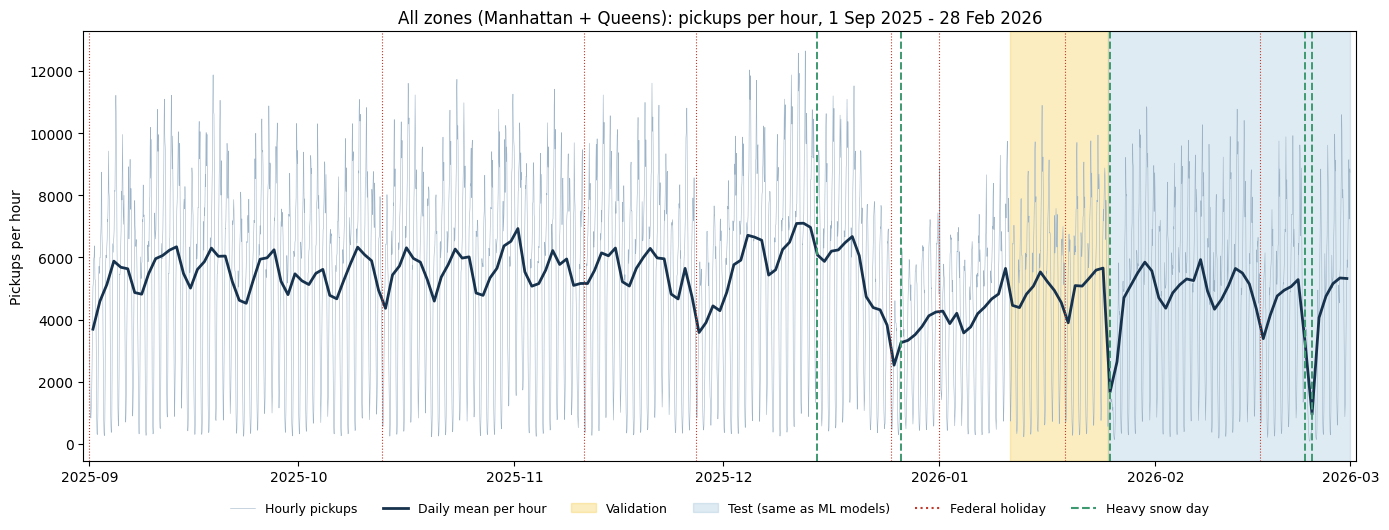

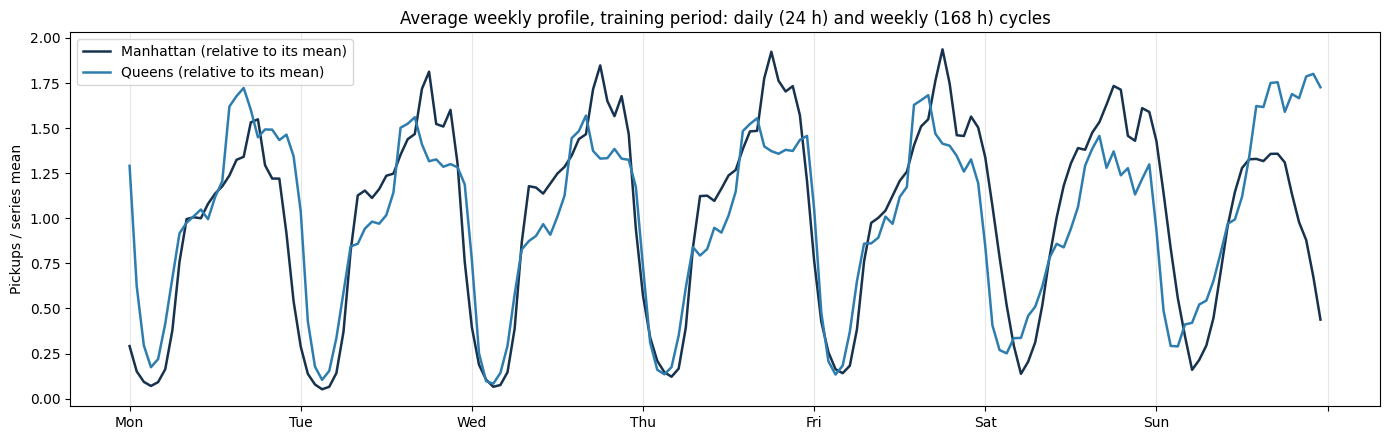

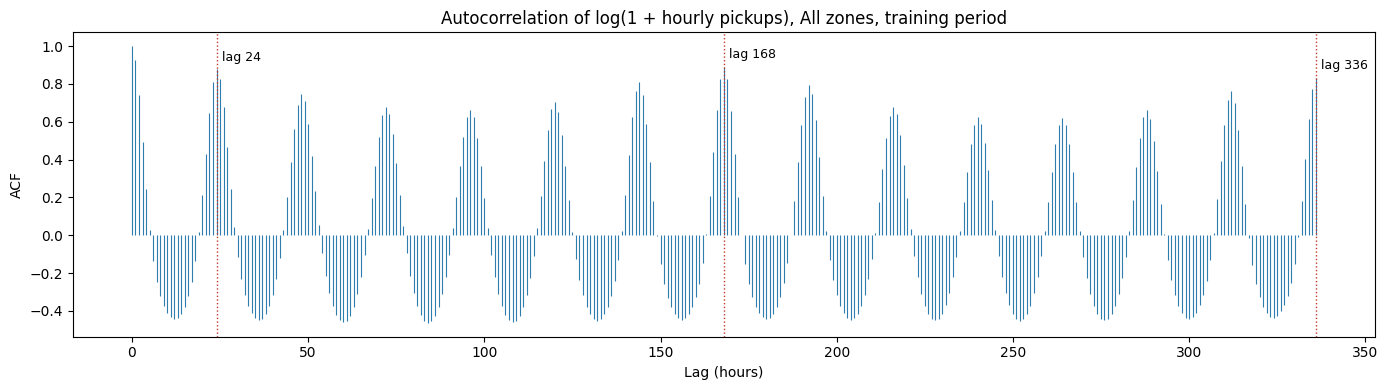

In [18]:
city_h = agg_hourly[agg_hourly["series_id"] == "All zones"].set_index("ds")
city_d = agg_daily[agg_daily["series_id"] == "All zones"].set_index("date")

fig, ax = plt.subplots(figsize=(14, 5.4))
ax.plot(city_h.index, city_h["trip_count_adj"], lw=0.4, color="#9db4c8", label="Hourly pickups")
ax.plot(city_d.index + pd.Timedelta(hours=12), city_d["trip_count_adj"] / 24, lw=2, color="#17324d", label="Daily mean per hour")
ax.axvspan(VAL_START, TEST_START, color="#f2b807", alpha=0.25, label="Validation")
ax.axvspan(TEST_START, END, color="#2e7daf", alpha=0.15, label="Test (same as ML models)")
for d in hol_in_window.index:
    ax.axvline(d, color="#c0392b", lw=0.8, ls=":")
for d in heavy_snow_days.index:
    ax.axvline(d + pd.Timedelta(hours=12), color="#3d9970", lw=1.4, ls="--")
ax.plot([], [], color="#c0392b", ls=":", label="Federal holiday"); ax.plot([], [], color="#3d9970", ls="--", label="Heavy snow day")
ax.set(title="All zones (Manhattan + Queens): pickups per hour, 1 Sep 2025 - 28 Feb 2026", ylabel="Pickups per hour")
ax.legend(ncol=6, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.07), frameon=False); ax.margins(x=0.005)
fig.tight_layout(); fig.savefig(FIG / "ts_all_zones_series.png", dpi=150); plt.show()

prof = (agg_hourly[(agg_hourly["series_level"] == "borough") & (agg_hourly["split"] == "train")]
        .groupby(["series_id", "hour_of_week"])["trip_count_adj"].mean().unstack(0))
fig, ax = plt.subplots(figsize=(14, 4.5))
for col, color in zip(prof.columns, ["#17324d", "#2e7daf"]):
    ax.plot(prof.index, prof[col] / prof[col].mean(), color=color, lw=1.8, label=f"{col} (relative to its mean)")
ax.set_xticks(range(0, 169, 24), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun", ""])
ax.set(title="Average weekly profile, training period: daily (24 h) and weekly (168 h) cycles", ylabel="Pickups / series mean")
ax.legend(); ax.grid(axis="x", alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "ts_weekly_profile.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
ax.vlines(range(len(acf_values)), 0, acf_values, color="#2e7daf", lw=0.8)
for lag in (24, 168, 336):
    ax.axvline(lag, color="#c0392b", ls=":", lw=1)
    ax.annotate(f"lag {lag}", (lag, acf_values[lag]), xytext=(4, 6), textcoords="offset points", fontsize=9)
ax.set(title="Autocorrelation of log(1 + hourly pickups), All zones, training period", xlabel="Lag (hours)", ylabel="ACF")
fig.tight_layout(); fig.savefig(FIG / "ts_acf.png", dpi=150); plt.show()

## 7. Feature catalogue and suitability checks

Every column in the five data tables is given a **role**, so it is always clear which columns a time series model may use as inputs. Using the wrong column is the easiest way to get misleadingly good results.

| Role | Meaning |
|---|---|
| `identifier` | Keys: series, zone, timestamp |
| `target` | `trip_count_adj`, the value to fit and forecast |
| `target_observed` | `trip_count`, the observed count. It equals the target except in the DST hour. Never an input |
| `target_transform` | $\log(1 + y)$ of the target. Never an input |
| `regressor_known_in_advance` | Calendar, holiday, event, DST and Fourier inputs, known at forecast time without any forecast |
| `regressor_needs_forecast` | Weather and weather-derived inputs. At forecast time they come from a weather forecast. Here they are observed values, so using them assumes a perfect forecast |
| `trend` | `t`, `day_index`, `week_index`: deterministic trend terms that extrapolate into the test period by design. Use with care over a six-month window |
| `descriptive` | For grouping, plots and analysis only, not model inputs: names that repeat a flag, `hour_of_week` (exactly `24 × day_of_week + hour`), `month` (February appears only in test), `day_of_month`, `n_zones` |
| `split` | Evaluation split labels |

The checks that follow make the rules concrete:
1. **Complete catalogue:** every column has exactly one role.
2. **No demand inside an input:** every known-in-advance regressor has the **same value for all six series** at a given hour, so it can't carry any information about demand. This is the check that `active_zones` (number of zones with a pickup in that hour) would have failed, and it has been removed.
3. **No extrapolation of inputs:** numeric known-in-advance regressors stay within their training range in validation and test, and categorical ones have no values that training never saw. This is why the holiday distances are capped and `iso_week` was dropped (it jumps from 52 back to 1 at New Year).
4. **No collinear inputs:** all numeric known-in-advance regressors together, plus an intercept, are full rank on the training data, and so are the 12 Fourier columns on their own. No input is an exact combination of others, which would break regression and ARIMA-with-regressors fits.

Weather ranges are only *reported*, not required to match. A snowstorm in the test period that is heavier than anything in training is real weather, not a data error.

In [19]:
CATALOG = {
    # identifiers and targets
    "series_level": ("identifier", "Aggregation level: city, borough or service_area"),
    "series_id": ("identifier", "Series name: All zones, Manhattan, Queens, Yellow Zone, Boro Zone, Airports"),
    "PULocationID": ("identifier", "TLC pickup zone"),
    "ds": ("identifier", "Start of the hour, naive local New York time"),
    "date": ("identifier", "Calendar day"),
    "trip_count_adj": ("target", "Pickups per physical hour (DST double hour halved); fit models on this"),
    "trip_count": ("target_observed", "Observed pickups; equals trip_count_adj except the DST hour; for evaluation, never an input"),
    "log1p_trip_count_adj": ("target_transform", "log(1 + trip_count_adj); variance-stabilised target, never an input"),
    # trend
    "t": ("trend", "Hours since 2025-09-01 00:00"),
    "day_index": ("trend", "Days since 2025-09-01"),
    "week_index": ("trend", "Monday-start weeks since 2025-09-01"),
    # known in advance
    "hour": ("regressor_known_in_advance", "Hour of day 0-23"),
    "day_of_week": ("regressor_known_in_advance", "0 = Monday ... 6 = Sunday"),
    "is_weekend": ("regressor_known_in_advance", "Saturday or Sunday"),
    "hour_of_week": ("descriptive", "Position in the weekly cycle, 0-167 (= 24 * day_of_week + hour); key for weekly profiles and seasonal-naive forecasts. Not an input next to hour and day_of_week: the three are exactly collinear"),
    "time_band": ("regressor_known_in_advance", "EDA time band of the hour"),
    "is_weekend_night": ("regressor_known_in_advance", "Friday or Saturday 20:00-04:59"),
    "is_holiday": ("regressor_known_in_advance", "US federal holiday"),
    "is_day_before_holiday": ("regressor_known_in_advance", "Day before a federal holiday"),
    "is_day_after_holiday": ("regressor_known_in_advance", "Day after a federal holiday"),
    "days_to_next_holiday": ("regressor_known_in_advance", f"Days to the next federal holiday, capped at {HOLIDAY_DISTANCE_CAP}"),
    "days_since_prev_holiday": ("regressor_known_in_advance", f"Days since the previous federal holiday, capped at {HOLIDAY_DISTANCE_CAP}"),
    "is_holiday_period": ("regressor_known_in_advance", "Thanksgiving week or Christmas-New Year period"),
    "is_special_day": ("regressor_known_in_advance", "Halloween, NYC Marathon, Black Friday, Christmas Eve or New Year's Eve"),
    "is_night_event": ("regressor_known_in_advance", "Halloween night or New Year's Eve night, 20:00-04:59"),
    "is_dst_merged_hour": ("regressor_known_in_advance", "2025-11-02 01:00, which holds two physical hours"),
    "is_dst_lag24_affected": ("regressor_known_in_advance", "Hour whose 24 h lag reads the DST hour"),
    "is_dst_lag168_affected": ("regressor_known_in_advance", "Hour whose 168 h lag reads the DST hour"),
    "contains_dst_merged_hour": ("regressor_known_in_advance", "Day that contains the DST double hour (daily tables)"),
    **{f"fourier_{p}_{f}_{k}": ("regressor_known_in_advance",
                                ("Daily cycle: " if p == "daily" else "Weekly cycle: ") +
                                (f"{f}(2*pi*{k}*hour/24)" if p == "daily" else
                                 f"{f}(2*pi*{k}*hour_of_week/168) in hourly tables, {f}(2*pi*{k}*day_of_week/7) in daily tables"))
       for p in ("daily", "weekly") for f in ("sin", "cos") for k in range(1, FOURIER_K + 1)},
    # needs a forecast
    **{v: ("regressor_needs_forecast", f"Hourly {v.replace('_', ' ')} (series tables: mean over the series' zones)") for v in WEATHER_VARS},
    "apparent_temperature_mean": ("regressor_needs_forecast", "Daily mean apparent temperature, C"),
    "apparent_temperature_min": ("regressor_needs_forecast", "Daily minimum apparent temperature, C"),
    "apparent_temperature_max": ("regressor_needs_forecast", "Daily maximum apparent temperature, C"),
    "rain_total": ("regressor_needs_forecast", "Daily rain total, mm"),
    "snowfall_total": ("regressor_needs_forecast", "Daily snowfall total, cm"),
    "precipitation_probability_mean": ("regressor_needs_forecast", "Daily mean precipitation probability, %"),
    "precipitation_probability_max": ("regressor_needs_forecast", "Daily maximum precipitation probability, %"),
    "rain_hours": ("regressor_needs_forecast", "Hours in the day with rain"),
    "snow_hours": ("regressor_needs_forecast", "Hours in the day with snowfall"),
    "is_heavy_snow_day": ("regressor_needs_forecast", "Zone-median daily snowfall >= 5 cm (weather-derived)"),
    # descriptive only
    "day_name": ("descriptive", "Weekday name (same information as day_of_week)"),
    "month": ("descriptive", "Calendar month; February occurs only in the test period, so not a model input"),
    "day_of_month": ("descriptive", "Day of the month"),
    "holiday_name": ("descriptive", "Holiday name or 'none'; MLK Day and Washington's Birthday occur only in validation/test, model with is_holiday"),
    "holiday_period": ("descriptive", "Holiday period name or 'none' (flag: is_holiday_period)"),
    "special_day_name": ("descriptive", "Special day name or 'none' (flag: is_special_day)"),
    "night_event_name": ("descriptive", "Night event name or 'none' (flag: is_night_event)"),
    "n_zones": ("descriptive", "Number of zones in the series (constant per series)"),
    # splits
    "split": ("split", "train / validation / test (daily tables: split of the calendar day)"),
    "split_daily": ("split", "Split of the calendar day the hour belongs to"),
}

data_tables = {"ts_calendar_hourly.csv": cal, "ts_aggregate_hourly.csv": agg_hourly, "ts_aggregate_daily.csv": agg_daily,
               "ts_zone_hourly.csv": zone_hourly, "ts_zone_daily.csv": zone_daily}
all_cols = set().union(*[set(df.columns) for df in data_tables.values()])
check("Every column has a role in the feature catalogue", all_cols == set(CATALOG),
      f"{len(all_cols)} distinct columns; missing {sorted(all_cols - set(CATALOG))}, unused {sorted(set(CATALOG) - all_cols)}")
feature_catalog = pd.DataFrame([{"column": c, "role": r, "tables": "; ".join(n for n, df in data_tables.items() if c in df.columns),
                                 "description": d} for c, (r, d) in CATALOG.items()])

known_hourly = [c for c, (r, _) in CATALOG.items() if r == "regressor_known_in_advance" and c in agg_hourly.columns]
known_daily = [c for c, (r, _) in CATALOG.items() if r == "regressor_known_in_advance" and c in agg_daily.columns]
check("Known-in-advance regressors carry no demand information",
      int(agg_hourly.groupby("ds")[known_hourly].nunique().max().max()) == 1 and int(agg_daily.groupby("date")[known_daily].nunique().max().max()) == 1,
      f"{len(known_hourly)} hourly / {len(known_daily)} daily regressors identical across all 6 series at every timestamp")


def range_problems(table, cols):
    train, later = table[table["split"] == "train"], table[table["split"] != "train"]
    problems = []
    for c in cols:
        if pd.api.types.is_bool_dtype(table[c]) or not pd.api.types.is_numeric_dtype(table[c]):
            if not set(later[c]) <= set(train[c]):
                problems.append(f"{c}: unseen {sorted(set(later[c]) - set(train[c]))}")
        elif later[c].min() < train[c].min() or later[c].max() > train[c].max():
            problems.append(f"{c}: {later[c].min()}..{later[c].max()} outside {train[c].min()}..{train[c].max()}")
    return problems


problems = range_problems(cal, known_hourly) + range_problems(agg_daily[agg_daily["series_id"] == "All zones"], known_daily)
check("Known-in-advance regressors stay inside their training range", not problems, "; ".join(problems) or "none outside")

num_known = [c for c in known_hourly if pd.api.types.is_numeric_dtype(cal[c])]
Xk = cal.loc[cal["split"] == "train", num_known].astype(float).assign(intercept=1.0).to_numpy()
check("Known-in-advance regressors are not exactly collinear", np.linalg.matrix_rank(Xk) == Xk.shape[1],
      f"{len(num_known)} numeric regressors + intercept: rank {np.linalg.matrix_rank(Xk)} of {Xk.shape[1]}")

fourier_cols = [c for c in cal.columns if c.startswith("fourier")]
X = cal.loc[cal["split"] == "train", fourier_cols].assign(intercept=1.0).to_numpy()
check("Fourier terms are not collinear", np.linalg.matrix_rank(X) == X.shape[1],
      f"rank {np.linalg.matrix_rank(X)} of {X.shape[1]}, condition number {np.linalg.cond(X):.1f}")

weather_ranges = (agg_hourly[agg_hourly["series_id"] == "All zones"].groupby("split")[WEATHER_VARS].agg(["min", "max"]).round(2))
print("Weather ranges by split (reported, not required to match):")
weather_ranges

[PASS] Every column has a role in the feature catalogue: 65 distinct columns; missing [], unused []
[PASS] Known-in-advance regressors carry no demand information: 28 hourly / 16 daily regressors identical across all 6 series at every timestamp
[PASS] Known-in-advance regressors stay inside their training range: none outside
[PASS] Known-in-advance regressors are not exactly collinear: 27 numeric regressors + intercept: rank 28 of 28
[PASS] Fourier terms are not collinear: rank 13 of 13, condition number 1.4
Weather ranges by split (reported, not required to match):


apparent_temperature        rain        snowfall       precipitation_probability        
                            min    max  min    max      min   max                       min     max
split                                                                                              
test                     -23.82   8.03  0.0   1.75      0.0  1.83                       0.0  100.00
train                    -14.16  32.69  0.0  16.30      0.0  1.76                       0.0  100.00
validation               -19.67   7.04  0.0   1.03      0.0  0.63                       0.0   93.77

## 8. Final checks and save

The last checks cover the whole dataset: no missing values anywhere, and weather that matches the source table. The outputs are then written to `data/processed/time_series/`.

In [20]:
outputs = {
    "ts_calendar_hourly.csv": cal,
    "ts_aggregate_hourly.csv": agg_hourly,
    "ts_aggregate_daily.csv": agg_daily,
    "ts_zone_hourly.csv": zone_hourly,
    "ts_zone_daily.csv": zone_daily,
    "ts_zone_profile.csv": profile,
    "ts_cv_folds.csv": cv_folds,
    "ts_stationarity_tests.csv": stationarity,
    "ts_acf_key_lags.csv": acf_table,
    "ts_feature_catalog.csv": feature_catalog,
}

for name in ["ts_calendar_hourly.csv", "ts_aggregate_hourly.csv", "ts_aggregate_daily.csv", "ts_zone_hourly.csv", "ts_zone_daily.csv"]:
    df = outputs[name]
    check(f"No missing values in {name}", int(df.isna().sum().sum()) == 0, f"{df.shape[0]:,} rows x {df.shape[1]} columns")
w_cmp = zone_hourly.merge(weather.rename(columns={"LocationID": "PULocationID", "weather_hour": "ds"})[["PULocationID", "ds", *WEATHER_VARS]],
                          on=["PULocationID", "ds"], suffixes=("", "_src"))
check("Zone weather matches the source table", all((w_cmp[v] == w_cmp[f"{v}_src"]).all() for v in WEATHER_VARS), f"{len(w_cmp):,} rows")

DATE_FMT = "%Y-%m-%d %H:%M:%S"
for name, df in outputs.items():
    df.to_csv(OUT / name, index=False, date_format=DATE_FMT)
# read every saved table back, the way a user would, and check nothing turned into a missing value
for name in ["ts_calendar_hourly.csv", "ts_aggregate_hourly.csv", "ts_aggregate_daily.csv", "ts_zone_hourly.csv",
             "ts_zone_daily.csv", "ts_cv_folds.csv"]:
    back = pd.read_csv(OUT / name)
    check(f"{name} reads back with no missing values", int(back.isna().sum().sum()) == 0, f"{len(back):,} rows re-read")
back = pd.read_csv(OUT / "ts_zone_profile.csv")
undefined = back.loc[back[["adi", "cv2"]].isna().any(axis=1), "PULocationID"].tolist()
check("ts_zone_profile.csv: only adi/cv2 of zero-demand zones are empty",
      int(back.drop(columns=["adi", "cv2"]).isna().sum().sum()) == 0 and undefined == profile.loc[profile["volume_tier"] == "Zero", "PULocationID"].tolist(),
      f"undefined for zones {undefined}")

checks = pd.DataFrame(CHECKS)
checks.to_csv(OUT / "ts_readiness_checks.csv", index=False)
outputs["ts_readiness_checks.csv"] = checks

summary = pd.DataFrame([{"file": n, "rows": len(df), "columns": df.shape[1],
                         "size_mb": round((OUT / n).stat().st_size / 1e6, 2)} for n, df in outputs.items()])
print(f"{len(checks)} checks, all passed: {checks['passed'].all()}")
summary

[PASS] No missing values in ts_calendar_hourly.csv: 4,344 rows x 44 columns
[PASS] No missing values in ts_aggregate_hourly.csv: 26,064 rows x 54 columns
[PASS] No missing values in ts_aggregate_daily.csv: 1,086 rows x 42 columns
[PASS] No missing values in ts_zone_hourly.csv: 599,472 rows x 8 columns
[PASS] No missing values in ts_zone_daily.csv: 24,978 rows x 14 columns


[PASS] Zone weather matches the source table: 599,472 rows


[PASS] ts_calendar_hourly.csv reads back with no missing values: 4,344 rows re-read


[PASS] ts_aggregate_hourly.csv reads back with no missing values: 26,064 rows re-read
[PASS] ts_aggregate_daily.csv reads back with no missing values: 1,086 rows re-read


[PASS] ts_zone_hourly.csv reads back with no missing values: 599,472 rows re-read
[PASS] ts_zone_daily.csv reads back with no missing values: 24,978 rows re-read
[PASS] ts_cv_folds.csv reads back with no missing values: 6 rows re-read
[PASS] ts_zone_profile.csv: only adi/cv2 of zero-demand zones are empty: undefined for zones [103, 104]
41 checks, all passed: True


,file,rows,columns,size_mb
0,ts_calendar_hourly.csv,4344,44,1.28
1,ts_aggregate_hourly.csv,26064,54,9.26
2,ts_aggregate_daily.csv,1086,42,0.28
3,ts_zone_hourly.csv,599472,8,27.99
4,ts_zone_daily.csv,24978,14,1.91
5,ts_zone_profile.csv,138,20,0.03
6,ts_cv_folds.csv,6,7,0.00
7,ts_stationarity_tests.csv,6,6,0.00
8,ts_acf_key_lags.csv,11,2,0.00
9,ts_feature_catalog.csv,65,4,0.01


## Output files

All in `data/processed/time_series/`. The full description of every field is in `data/dataset-documents/time_series_preparation.md`.

| File | Grain | Use it for |
|---|---|---|
| `ts_aggregate_hourly.csv` | 6 series × 4,344 hours | Hourly analysis of city, borough and service-area demand; all calendar fields included |
| `ts_aggregate_daily.csv` | 6 series × 181 days | Daily decomposition, weekly SARIMA, ETS |
| `ts_zone_hourly.csv` | 138 zones × 4,344 hours | Zone-level forecasting; join `ts_calendar_hourly.csv` on `ds` |
| `ts_zone_daily.csv` | 138 zones × 181 days | Daily zone-level analysis |
| `ts_calendar_hourly.csv` | 4,344 hours | Calendar, events, Fourier terms, DST flags and splits |
| `ts_zone_profile.csv` | 138 zones | Volume tier, demand pattern and suggested approach per zone (training period only) |
| `ts_cv_folds.csv` | 6 folds | Rolling-origin evaluation windows |
| `ts_stationarity_tests.csv`, `ts_acf_key_lags.csv` | diagnostics | Starting points for differencing orders and seasonal periods |
| `ts_feature_catalog.csv` | every column | Role of each column (target, regressor, descriptive ...) and its description |
| `ts_readiness_checks.csv` | all checks | Every check in this notebook and its result |